# Part 2A

## Imports

In [5]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Imports Complete")

Imports Complete


## Load training data

In [10]:
splits = joblib.load("../data/part2a_splits.joblib")
X_train, X_test = splits["X_train"], splits["X_test"]
y_train, y_test = splits["y_train"], splits["y_test"]
w_train, w_test = splits["w_train"], splits["w_test"]

print("Successfully loaded test data")

Successfully loaded test data


## setup one hot encoding

In [7]:
X_train_enc = pd.get_dummies(X_train.astype("object"), dummy_na=True)
X_test_enc = pd.get_dummies(X_test.astype("object"), dummy_na=True).reindex(
    columns=X_train_enc.columns, fill_value=0
)

## baseline v models

In [8]:
models = {
    "Baseline (Majority Class)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_enc, y_train, sample_weight=w_train)
    preds = model.predict(X_test_enc)
    acc = accuracy_score(y_test, preds, sample_weight=w_test)
    print(f"{name:28s} | Weighted Accuracy: {acc:.4f}")


Baseline (Majority Class)    | Weighted Accuracy: 0.3493
Decision Tree                | Weighted Accuracy: 0.3520
Logistic Regression          | Weighted Accuracy: 0.3521


## matrix display


Classification Report:
              precision    recall  f1-score   support

       18-29      0.393     0.173     0.241 1345.7520500403903
       30-49      0.354     0.809     0.492 1953.7265297021816
       50-64      0.244     0.004     0.009 1300.3817728146532
         65+      0.293     0.151     0.199 992.8883199327074

    accuracy                          0.352 5592.748672489933
   macro avg      0.321     0.284     0.235 5592.748672489933
weighted avg      0.327     0.352     0.267 5592.748672489933



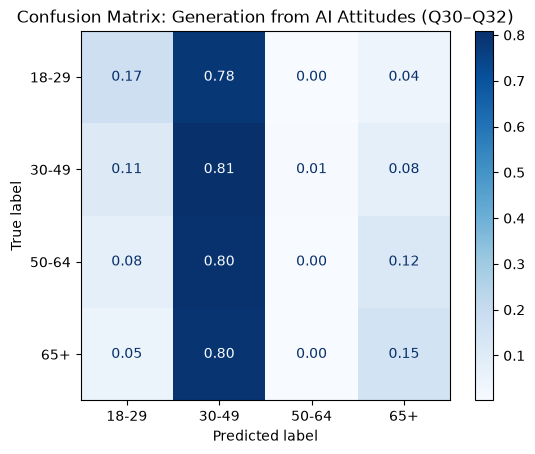

In [9]:
lr = models["Logistic Regression"]
y_pred = lr.predict(X_test_enc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, sample_weight=w_test, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, sample_weight=w_test, normalize="true", cmap="Blues", values_format=".2f"
)
plt.title("Confusion Matrix: Generation from AI Attitudes (Q30–Q32)")
plt.show()